# Predictive Energy Consumption Analytics
## Phase 2: Exploratory Data Analysis (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Create output directories if they don't exist
os.makedirs('../outputs/figures', exist_ok=True)

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)


### 1. Data Loading and Verification
Loading the cleaned dataset, verifying columns, and checking data types.

In [2]:
df = pd.read_csv('../data/processed/cleaned_energy_dataset.csv')
df['Date'] = pd.to_datetime(df['Date'])
df.set_index('Date', inplace=True)

print(df.info())
print("\nMissing values:\n", df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 73 entries, 2026-07-01 to 2026-09-11
Data columns (total 12 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Month                               73 non-null     object 
 1   TNEB Campus HTSC-91                 73 non-null     float64
 2   TNEB New STP HTSC-178               73 non-null     float64
 3   Power Generation by Solar Panels    73 non-null     float64
 4   Power Generation by Diesel Engines  73 non-null     float64
 5   Power Generation by Biogas Engines  73 non-null     float64
 6   Staff Quarters                      73 non-null     float64
 7   Academic blocks                     73 non-null     float64
 8   Hostels                             73 non-null     float64
 9   Chiller plant                       73 non-null     float64
 10  STP                                 73 non-null     float64
 11  Total Consumption          

**Note on Data Preparation**: 6 entirely empty rows at the bottom were dropped in Phase 1. Missing values in the `Chiller plant` column (which contained non-numeric strings) were coerced to NaN and interpolated linearly. `Total Consumption` is treated as the primary target variable and not manually recalculated.

### 2. Descriptive Statistics
Exporting the summary statistics to `outputs/`.

In [3]:
desc_stats = df.describe()
desc_stats.to_csv('../outputs/summary_statistics.csv')
display(desc_stats)


,TNEB Campus HTSC-91,TNEB New STP HTSC-178,Power Generation by Solar Panels,Power Generation by Diesel Engines,Power Generation by Biogas Engines,Staff Quarters,Academic blocks,Hostels,Chiller plant,STP,Total Consumption
count,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000,73.000000
mean,18446.849315,810.082192,4860.835616,274.863014,546.698630,1960.589041,10846.917808,7030.835616,3638.698630,1353.356164,24754.342466
std,4144.219829,148.952803,1098.725866,755.583059,190.822247,114.680212,2070.958130,1813.256486,1966.516808,160.972252,4563.451013
min,8460.000000,532.000000,1868.000000,0.000000,77.000000,1738.000000,6929.000000,769.000000,0.000000,896.000000,13203.000000
25%,15440.000000,718.000000,4001.000000,0.000000,421.000000,1892.000000,9148.000000,6345.000000,2419.000000,1254.000000,21570.000000
50%,19900.000000,790.000000,4926.000000,0.000000,528.000000,1961.000000,11432.000000,6979.000000,4314.000000,1364.000000,25540.000000
75%,21420.000000,906.000000,5735.000000,160.000000,671.000000,2035.000000,12144.000000,7805.000000,4860.000000,1456.000000,27860.000000
max,26620.000000,1388.000000,6801.000000,5192.000000,1032.000000,2239.000000,16384.000000,10362.000000,6874.000000,1720.000000,34038.000000


### 3. Daily Total Consumption Trend

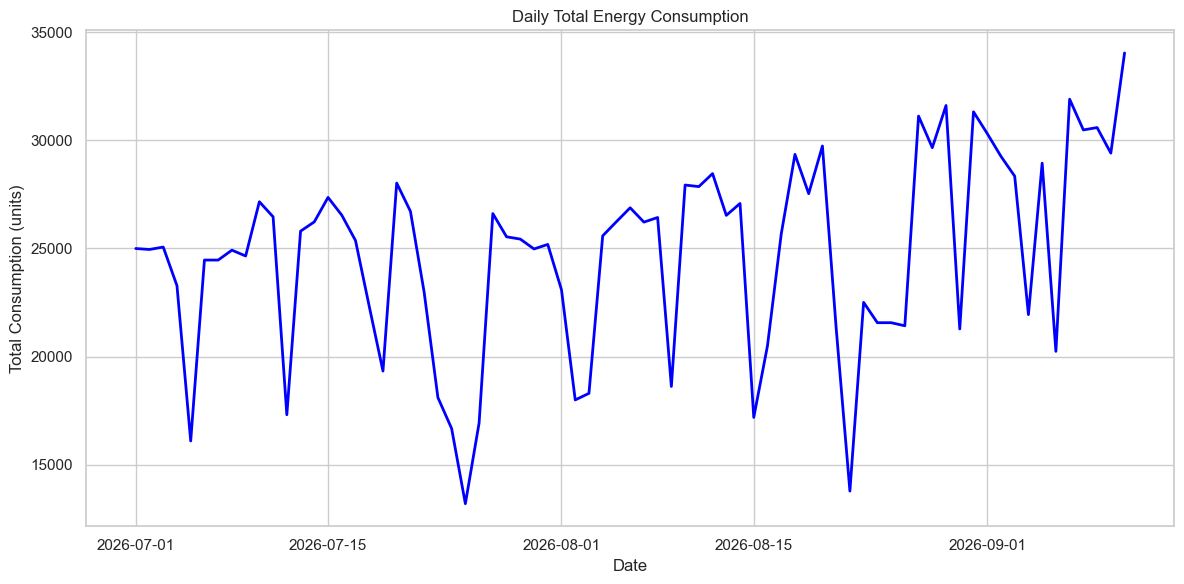

In [4]:
plt.figure()
plt.plot(df.index, df['Total Consumption'], color='blue', linewidth=2)
plt.title('Daily Total Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Total Consumption (units)')
plt.tight_layout()
plt.savefig('../outputs/figures/daily_total_consumption.png')
plt.show()


### 4. Monthly Trends
Note: The dataset only spans three months (July, August, September), making it insufficient to derive long-term seasonal patterns.

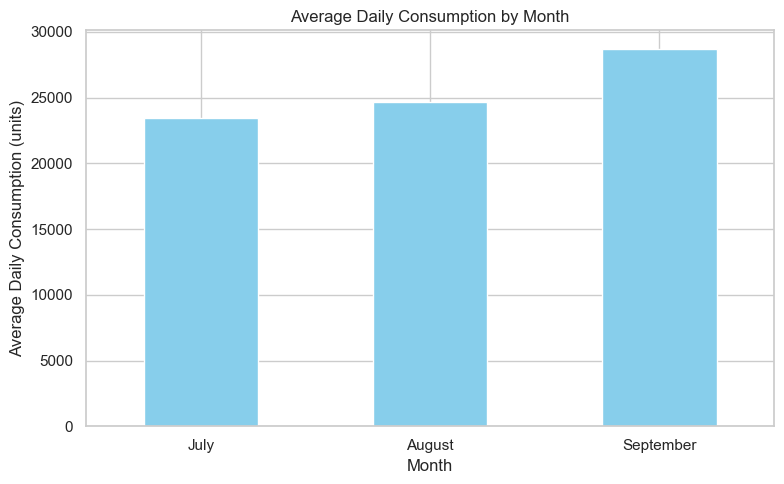

In [5]:
monthly_avg = df.groupby('Month')['Total Consumption'].mean().reindex(['July', 'August', 'September'])
plt.figure(figsize=(8, 5))
monthly_avg.plot(kind='bar', color='skyblue')
plt.title('Average Daily Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Consumption (units)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../outputs/figures/monthly_average_consumption.png')
plt.show()


### 5. Infrastructure-Wise Consumption

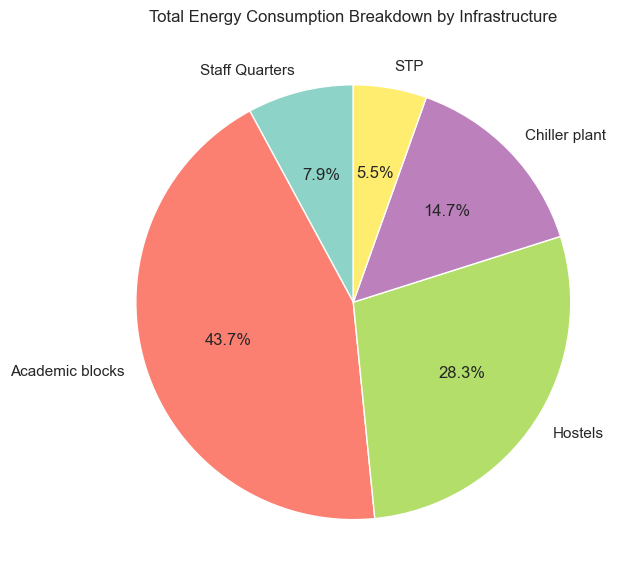

In [6]:
infra_cols = ['Staff Quarters', 'Academic blocks', 'Hostels', 'Chiller plant', 'STP']
infra_sum = df[infra_cols].sum()

plt.figure(figsize=(10, 6))
infra_sum.plot(kind='pie', autopct='%1.1f%%', startangle=90, cmap='Set3')
plt.title('Total Energy Consumption Breakdown by Infrastructure')
plt.ylabel('')
plt.tight_layout()
plt.savefig('../outputs/figures/infrastructure_consumption_pie.png')
plt.show()


### 6. Power Generation Trends

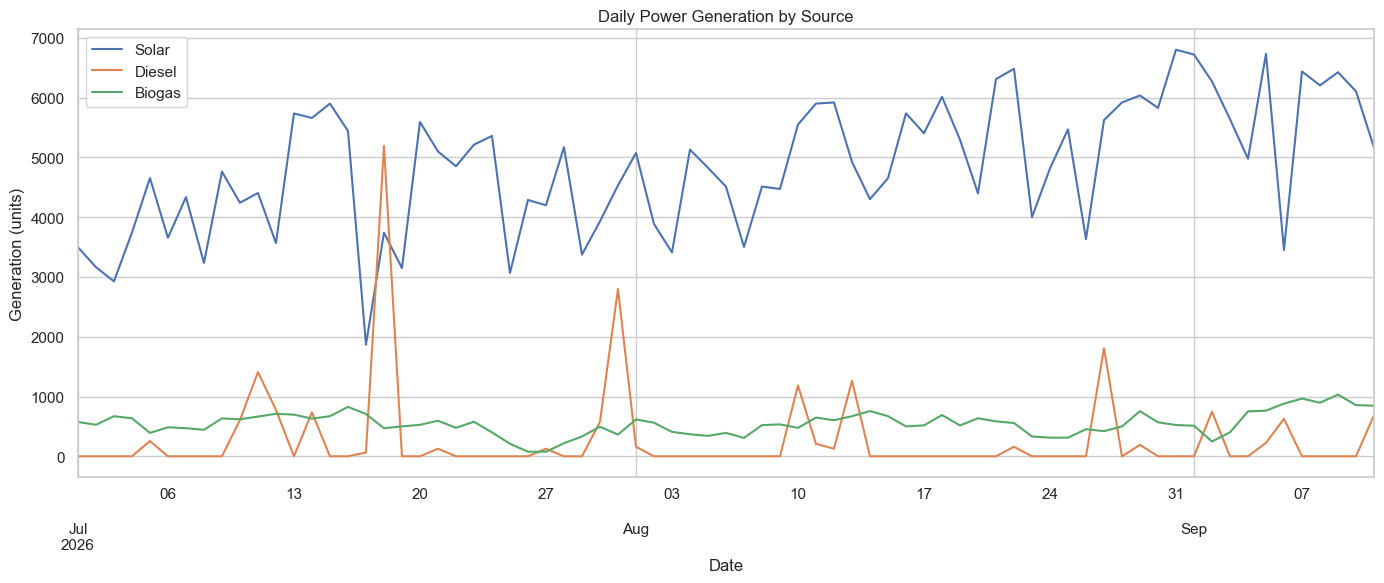

In [7]:
gen_cols = ['Power Generation by Solar Panels', 'Power Generation by Diesel Engines', 'Power Generation by Biogas Engines']
df[gen_cols].plot(figsize=(14, 6))
plt.title('Daily Power Generation by Source')
plt.xlabel('Date')
plt.ylabel('Generation (units)')
plt.legend(['Solar', 'Diesel', 'Biogas'])
plt.tight_layout()
plt.savefig('../outputs/figures/generation_trends.png')
plt.show()


### 7. Weekday vs Weekend Patterns
Analyzing whether consumption drops on weekends.

C:\Users\SIBI-007\AppData\Local\Temp\ipykernel_13436\3347870258.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='IsWeekend', y='Total Consumption', data=df, palette='Set2')


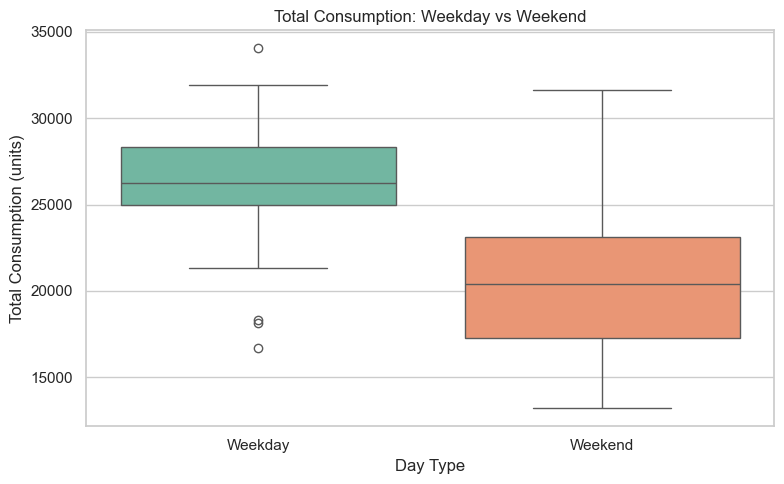

IsWeekend
Weekday    26224.339623
Weekend    20858.850000
Name: Total Consumption, dtype: float64


In [8]:
df['DayOfWeek'] = df.index.dayofweek
df['IsWeekend'] = df['DayOfWeek'].apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

plt.figure(figsize=(8, 5))
sns.boxplot(x='IsWeekend', y='Total Consumption', data=df, palette='Set2')
plt.title('Total Consumption: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Total Consumption (units)')
plt.tight_layout()
plt.savefig('../outputs/figures/weekday_vs_weekend_boxplot.png')
plt.show()

weekend_stats = df.groupby('IsWeekend')['Total Consumption'].mean()
print(weekend_stats)


### 8. Peak and Low Consumption Days

In [9]:
peak_date = df['Total Consumption'].idxmax()
low_date = df['Total Consumption'].idxmin()

peak_val = df.loc[peak_date, 'Total Consumption']
low_val = df.loc[low_date, 'Total Consumption']

peak_low_df = pd.DataFrame({
    'Metric': ['Peak Consumption', 'Low Consumption'],
    'Date': [peak_date.date(), low_date.date()],
    'Consumption (units)': [peak_val, low_val]
})

peak_low_df.to_csv('../outputs/peak_low_consumption.csv', index=False)
display(peak_low_df)


,Metric,Date,Consumption (units)
0,Peak Consumption,2026-09-11,34038.0
1,Low Consumption,2026-07-25,13203.0


### 9. Correlation Analysis
Examining linear relationships between consumption sources, generation, and total consumption.

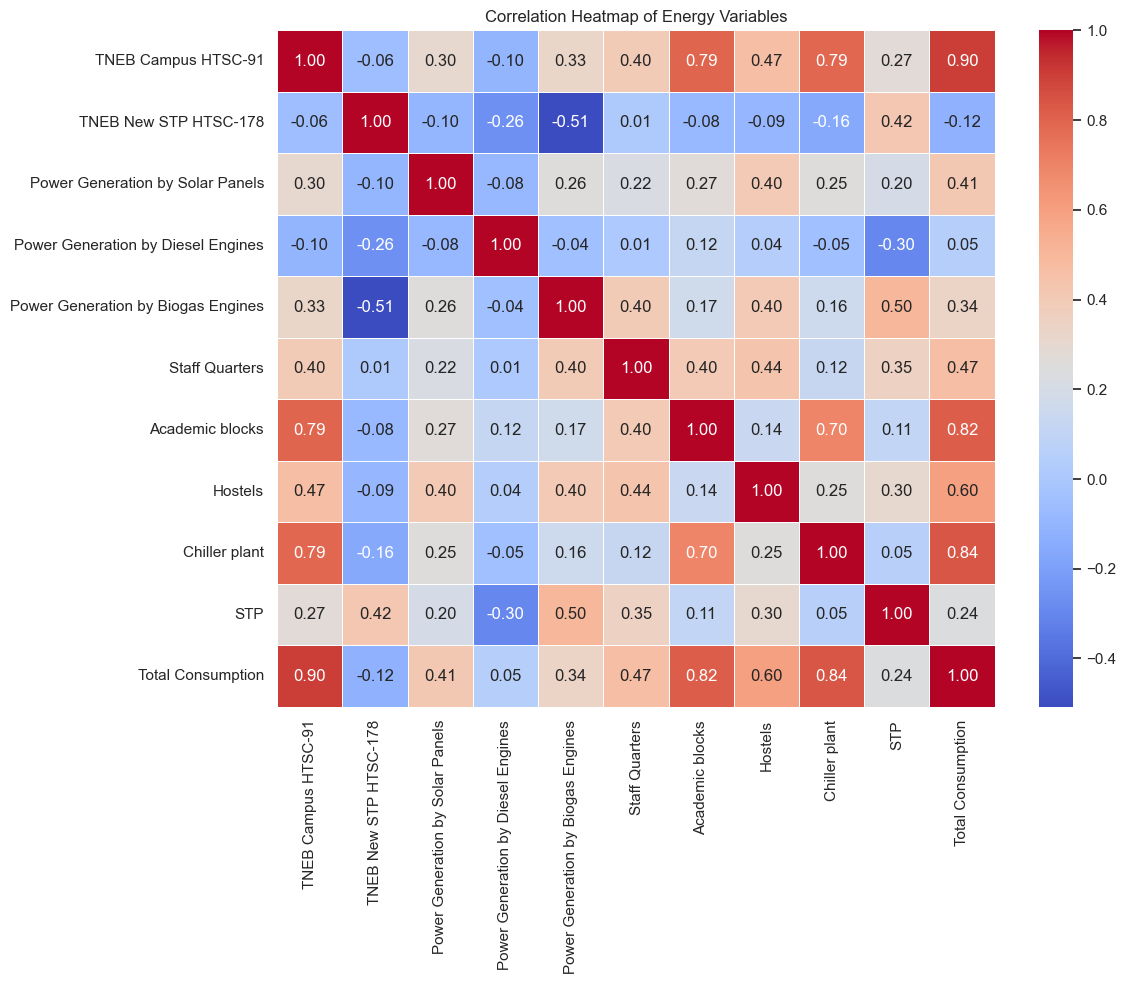

In [10]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
# Exclude DayOfWeek 
numeric_cols = [c for c in numeric_cols if c not in ['DayOfWeek']]
corr = df[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Energy Variables')
plt.tight_layout()
plt.savefig('../outputs/figures/correlation_heatmap.png')
plt.show()


### 10. Key Findings & Observations
- **Daily Trends**: Total consumption fluctuates heavily, with notable drops likely corresponding to weekends.
- **Weekend Effect**: The boxplot confirms that energy consumption is significantly lower on weekends compared to weekdays, which is typical for academic environments.
- **Generation**: Solar power is consistently the highest secondary generation source, whereas diesel is used sporadically (likely as a backup). Biogas is consistently low but stable.
- **Infrastructure**: Academic blocks consume the lion's share of energy, followed by Hostels.
- **Correlation**: `Total Consumption` is highly correlated with `Academic blocks` and `TNEB Campus HTSC-91` (the main grid). `Solar Generation` shows a modest negative or weak correlation with specific consumptions, indicating it supplements the grid during high-sun hours.
- **Data Integrity Note**: No obvious data leakage in this retrospective EDA. It's confirmed that all values represent daily consumption rather than cumulative meter readings because they fluctuate up and down daily instead of strictly increasing.
- **Limitations**: We only have data for July, August, and part of September. Annual seasonality (e.g., winter heating vs summer cooling) cannot be deduced from this small window.